In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def cylinder_panels(n,r=1):
  theta=np.linspace(2*np.pi,0,n+1)
  x=r*np.cos(theta)
  y=r*np.sin(theta)
  return(x,y)

In [4]:
def naca4_panels(code, n, spacing="cosine"):
    m = int(code[0]) / 100        # max camber
    p = int(code[1]) / 10         # location of max camber
    t = int(code[2:]) / 100       # thickness

    half = n // 2
    if spacing == "cosine":
        beta = np.linspace(0, np.pi, half + 1)
        x = 0.5 * (1 - np.cos(beta))
    else:                          # uniform
        x = np.linspace(0, 1, half + 1)

    # thickness distribution (-0.1036 makes the trailing edge closed)
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2
              + 0.2843*x**3 - 0.1036*x**4)

    # camber line and its slope
    if m == 0:
        yc = np.zeros_like(x)
        dyc = np.zeros_like(x)
    else:
        yc = np.where(x < p,
                      m/p**2 * (2*p*x - x**2),
                      m/(1-p)**2 * ((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p,
                       2*m/p**2 * (p - x),
                       2*m/(1-p)**2 * (p - x))
    th = np.arctan(dyc)

    xu = x - yt*np.sin(th);  yu = yc + yt*np.cos(th)
    xl = x + yt*np.sin(th);  yl = yc - yt*np.cos(th)

    # clockwise: lower surface from TE to LE, then upper surface LE to TE
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    return xb, yb

In [5]:
def panel_geometry(xb, yb):
    dx = np.diff(xb)
    dy = np.diff(yb)
    xc = 0.5 * (xb[:-1] + xb[1:])      # control points (midpoints)
    yc = 0.5 * (yb[:-1] + yb[1:])
    S = np.hypot(dx, dy)                # panel lengths
    sin_t = dy / S                      # panel angle (relative to x-axis)
    cos_t = dx / S
    return xc, yc, S, sin_t, cos_t

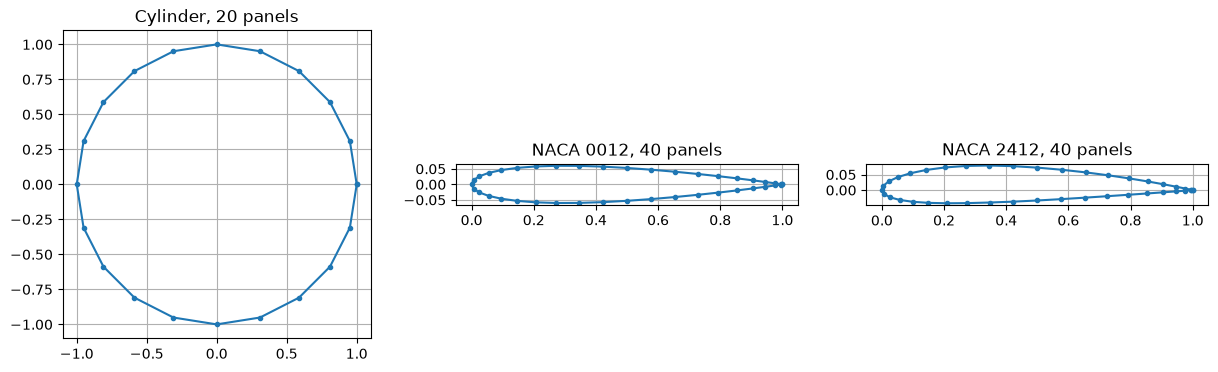

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, 20 panels": cylinder_panels(20),
        "NACA 0012, 40 panels": naca4_panels("0012", 40),
        "NACA 2412, 40 panels": naca4_panels("2412", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3)
    a.set_aspect("equal"); a.set_title(name); a.grid(True)
plt.show()

## Defining Vortex panel method

In [7]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    
    alpha = np.radians(alpha_deg)
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

                                                # influence-coefficient matrix
    A = np.zeros((N, N))
    for i in range(N):
        for j in range(N):
            if i == j:
                continue                       # self-influence on normal velocity = 0
            dx = xc[i] - xb[j]
            dy = yc[i] - yb[j]
            xi  =  dx*cos_t[j] + dy*sin_t[j]   # local coordinates of point i
            eta = -dx*sin_t[j] + dy*cos_t[j]   # in panel j's frame
            th1 = np.arctan2(eta, xi)
            th2 = np.arctan2(eta, xi - S[j])
            r1 = np.hypot(xi, eta)
            r2 = np.hypot(xi - S[j], eta)
            A[i, j] = ((th2 - th1)*np.sin(theta[j] - theta[i])
                       + np.log(r2/r1)*np.cos(theta[i] - theta[j])) / (2*np.pi)
# first term: along-panel velocity of j, second term: across-panel velocity of j
   
    b = V_inf*np.sin(theta - alpha)

                                              # Kutta condition replaces the last equation
    A[-1, :] = 0.0
    A[-1, 0] = 1.0
    A[-1, -1] = 1.0
    b[-1] = 0.0

   
    gamma = np.linalg.solve(A, b)

    Cp = 1 - (gamma/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(gamma*S)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "xc": xc, "yc": yc, "S": S}

### `vortex_panel_method_0`: Constant-Strength Vortex Panels

**Goal:** Find the vortex strength γ on each panel so that no flow passes through the body, then compute Cp and Cl.

- **Inputs:** `xb, yb` (boundary points), `alpha_deg`, `V_inf`
- **Outputs:** `gamma`, `Cp`, `Cl`, `xc`, `yc`, `S`

**Steps:**
1. Get each panel's midpoint, length `S` and angle `theta`.
2. Build matrix `A`: `A[i, j]` is the normal velocity at panel i caused by panel j with unit strength.
3. Set the self-term `A[i, i] = 0`.
4. Build `b` from the free stream: `b = V_inf * sin(theta - alpha)`.
5. Add the Kutta condition `gamma[0] + gamma[N-1] = 0` as an extra equation. It fixes the circulation so the flow leaves the trailing edge smoothly.
6. Solve with `np.linalg.lstsq`. The `rcond` setting removes the zig-zag mode that gives spiky Cp.
7. Compute results:
   - `Cp = 1 - (gamma / V_inf)**2`
   - `Gamma = sum(gamma * S)`
   - `Cl = 2 * Gamma / (V_inf * chord)`

N =   11   max |Cp error| = 1.0871   Cl = -2.49e-15
N =   21   max |Cp error| = 0.5500   Cl = -2.07e-14
N =   41   max |Cp error| = 0.2763   Cl = -2.32e-14
N =   81   max |Cp error| = 0.1384   Cl = 2.67e-14
N =  161   max |Cp error| = 0.0693   Cl = 3.91e-14


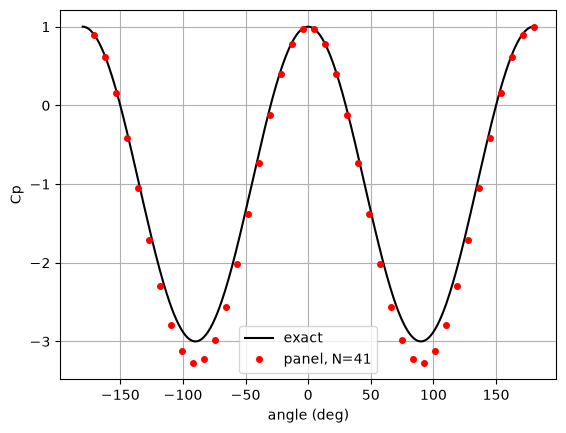

NACA0012, 5 deg, Cl = 0.6047648353301915


In [8]:
# Cylinder: exact solution is Cp = 1 - 4 sin^2(phi), and Cl = 0
# Odd numbers are used to avoid symmetry-related numerical issues and to keep stagnation points away from panel boundaries, resulting in more stable and accurate vortex-panel solutions.
for n in [11, 21, 41, 81, 161]:                                      
    xb, yb = cylinder_panels(n)
    r = vortex_panel_method_0(xb, yb, 0.0)
    phi = np.arctan2(r["yc"], r["xc"])
    err = np.max(np.abs(r["Cp"] - (1 - 4*np.sin(phi)**2)))
    print(f"N = {n:4d}   max |Cp error| = {err:.4f}   Cl = {r['Cl']:.2e}")

# Compare with the exact curve for N = 41
xb, yb = cylinder_panels(41)
r = vortex_panel_method_0(xb, yb, 0.0)
phi = np.arctan2(r["yc"], r["xc"])
pe = np.linspace(-np.pi, np.pi, 400)
plt.plot(np.degrees(pe), 1 - 4*np.sin(pe)**2, "k", label="exact")
plt.plot(np.degrees(phi), r["Cp"], "ro", ms=4, label="panel, N=41")
plt.xlabel("angle (deg)"); plt.ylabel("Cp"); plt.legend(); plt.grid(True)
plt.show()

# Quick airfoil sanity check: NACA 0012 at 5 deg, expect Cl a bit above 0.55
xb, yb = naca4_panels("0012", 160)
print("NACA0012, 5 deg, Cl =", vortex_panel_method_0(xb, yb, 5.0)["Cl"])

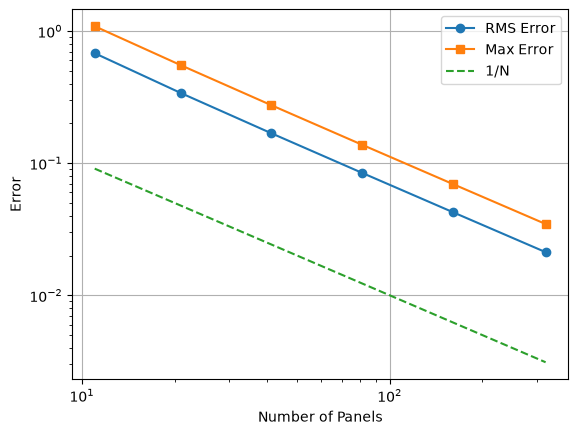

In [9]:
Ns = [11, 21, 41, 81, 161, 321]

max_err = []
rms_err = []

for N in Ns:

    # Create cylinder mesh
    xb, yb = cylinder_panels(N)

    # Solve panel method
    result = vortex_panel_method_0(xb, yb, 0.0)

    # Angle of each control point
    phi = np.arctan2(result["yc"], result["xc"])

    # Exact Cp
    Cp_exact = 1 - 4*np.sin(phi)**2

    # Numerical Cp
    Cp_num = result["Cp"]

    # Error
    error = np.abs(Cp_num - Cp_exact)

    # Store errors
    max_err.append(np.max(error))
    rms_err.append(np.sqrt(np.mean(error**2)))

# Plot error convergence
plt.loglog(Ns, rms_err, 'o-', label="RMS Error")
plt.loglog(Ns, max_err, 's-', label="Max Error")
plt.loglog(Ns, 1/np.array(Ns), '--', label="1/N")                  #order 1

plt.xlabel("Number of Panels")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()

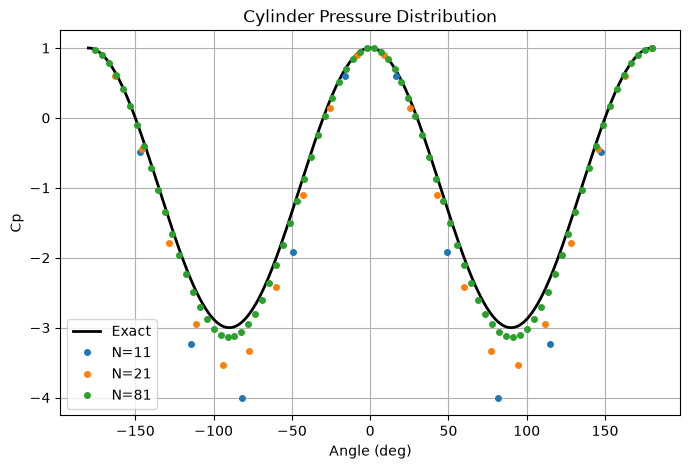

In [10]:
plt.figure(figsize=(8,5))

phi_exact = np.linspace(-np.pi, np.pi, 400)
Cp_exact = 1 - 4*np.sin(phi_exact)**2

plt.plot(np.degrees(phi_exact),
         Cp_exact,
         'k',
         linewidth=2,
         label='Exact')

for N in [11, 21, 81]:
    xb, yb = cylinder_panels(N)
    result = vortex_panel_method_0(xb, yb, 0.0)

    phi = np.arctan2(result["yc"], result["xc"])

    plt.plot(np.degrees(phi),result["Cp"],'o',markersize=4,label=f'N={N}')

plt.xlabel("Angle (deg)")
plt.ylabel("Cp")
plt.title("Cylinder Pressure Distribution")
plt.legend()
plt.grid(True)
plt.show()

### Cylinder Pressure Distribution: Panel Method vs Exact Solution
#### What this graph tells

1. **Exact solution**
   - Make 400 angles from -180° to +180°.
   - For a cylinder in potential flow with no circulation, the exact pressure coefficient is `Cp = 1 - 4 sin²(φ)`.
   - This is plotted as a thick black line.

2. **Panel method solution**
   - Take three panel counts: N = 11, 21 and 81.
   - For each N, create the circle with `cylinder_panels(N)`.
   - Solve the flow with `vortex_panel_method_0` at angle of attack 0° (the angle does not matter for a cylinder).
   - The function returns Cp at the middle point (control point) of every panel.

3. **Finding the angle of each point**
   - `np.arctan2(yc, xc)` gives the angle φ of each control point.
   - This lets us plot the panel results at the same angles as the exact curve.

4. **Plotting**
   - The panel results are drawn as dots, one colour for each N.
   - Labels, title, legend and grid are added to make the plot readable.

**What the plot shows:**

- The dots follow the black curve, so the method works.
- Cp = 1 at the front and back of the cylinder (stagnation points).
- Cp = -3 at the top and bottom (lowest pressure).
- With more panels the dots get closer to the exact curve (N = 81 is almost exact).
- The error is largest at the top and bottom, where the pressure changes fastest.

**Conclusion:** As the number of panels increases, the panel method solution converges to the exact solution.

## Now defining vortex panel method_1-Linear-Strength Vortex Panels

In [11]:
def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0):
    alpha = np.radians(alpha_deg)             #convert to radians
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

    A = np.zeros((N + 1, N + 1))               #building the matrix
    for i in range(N):
        for j in range(N):
            if i == j:                                   # control point on its own panel,panel acting on itself
                xi, eta, Dth, L = S[j]/2, 0.0, np.pi, 0.0
            else:
                dx = xc[i] - xb[j]
                dy = yc[i] - yb[j]
                xi  =  dx*cos_t[j] + dy*sin_t[j]
                eta = -dx*sin_t[j] + dy*cos_t[j]
                th1 = np.arctan2(eta, xi)
                th2 = np.arctan2(eta, xi - S[j])
                r1 = np.hypot(xi, eta)
                r2 = np.hypot(xi - S[j], eta)
                Dth = th2 - th1                     #angle the panel subtends at the point
                L = np.log(r2/r1)
# J: effect of the constant part of gamma on the panel
# K: effect of the linearly varying part of gamma (extra xi0 factor)
# 1 = velocity along the panel, 2 = velocity across (normal to) the panel
            J1 = Dth
            J2 = -L
            K1 = xi*Dth + eta*L
            K2 = -xi*L - S[j] + eta*Dth

            # local velocity per unit gamma_j (a) and per unit gamma_{j+1} (b)
            uxi_a  =  (J1 - K1/S[j]) / (2*np.pi)
            uxi_b  =  (K1/S[j])      / (2*np.pi)
            ueta_a = -(J2 - K2/S[j]) / (2*np.pi)
            ueta_b = -(K2/S[j])      / (2*np.pi)

            s = np.sin(theta[j] - theta[i])
            c = np.cos(theta[i] - theta[j])
# normal velocity at i due to panel j: gamma[j] part -> column j, gamma[j+1] part -> column j+1
# (+= because shared nodes receive contributions from two panels)
            A[i, j]     += uxi_a*s + ueta_a*c            # the previous term is added
            A[i, j + 1] += uxi_b*s + ueta_b*c

    b = np.zeros(N + 1)
    b[:N] = V_inf*np.sin(theta - alpha)

    # Kutta condition: gamma_1 + gamma_{N+1} = 0
    A[N, 0] = 1.0
    A[N, N] = 1.0
    b[N] = 0.0

    gamma = np.linalg.solve(A, b)

    Vt = 0.5*(gamma[:-1] + gamma[1:])          # surface speed at control points
    Cp = 1 - (Vt/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(S*Vt)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "xc": xc, "yc": yc, "S": S}

### `vortex_panel_method_1`: Linear-Strength Vortex Panels

**Goal:** Find the vortex strength at each boundary point, with γ varying linearly along each panel, so that no flow passes through the body. Then compute Cp and Cl.

- **Inputs:** `xb, yb` (boundary points), `alpha_deg`, `V_inf`
- **Outputs:** `gamma` (N+1 nodal values), `Cp`, `Cl`, `xc`, `yc`, `S`

**Steps:**
1. Get each panel's midpoint, length `S` and angle `theta`.
2. There are N+1 unknowns (one γ per boundary point), so `A` is an (N+1) × (N+1) matrix.
3. For each pair of panels, express point i in panel j's own axes and compute `th1`, `th2`, `r1`, `r2`, `Dth` and `L`.
4. Compute `J1`, `J2`, `K1`, `K2`. These are the integrals that account for γ changing along the panel.
5. Each panel j affects two unknowns, `gamma[j]` and `gamma[j+1]`:
   - `A[i, j]` gets the part due to `gamma[j]`.
   - `A[i, j+1]` gets the part due to `gamma[j+1]`.
6. For i = j (a panel acting on its own midpoint), use the special values `xi = S/2`, `eta = 0`, `Dth = π`, `L = 0`.
7. Build `b` from the free stream: `b = V_inf * sin(theta - alpha)`. The last entry is 0.
8. Kutta condition: `gamma[0] + gamma[N] = 0` is the extra (N+1)th equation, so no row has to be replaced.
9. Solve with `np.linalg.solve`.
10. Compute results:
    - Surface speed at each midpoint: `Vt = (gamma[i] + gamma[i+1]) / 2`
    - `Cp = 1 - (Vt / V_inf)**2`
    - `Gamma = sum(S * Vt)`
    - `Cl = 2 * Gamma / (V_inf * chord)`

**Compared with method 0:** the error falls about 4 times when the panels are doubled (second order, against first order for method 0), and it gives smoother Cp on airfoils.

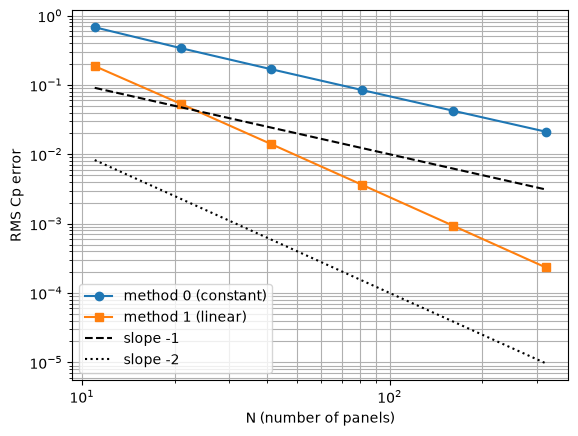

N   11 ->   21:  order m0 = 1.00,  order m1 = 1.82
N   21 ->   41:  order m0 = 1.00,  order m1 = 1.91
N   41 ->   81:  order m0 = 1.00,  order m1 = 1.95
N   81 ->  161:  order m0 = 1.00,  order m1 = 1.98
N  161 ->  321:  order m0 = 1.00,  order m1 = 1.99
0012 Cl method 0 = 0.6048  method 1 = 0.6029
2412 Cl method 0 = 0.8652  method 1 = 0.8615


In [12]:
panel_counts = [11, 21, 41, 81, 161, 321]     # number of panels N (odd values for the cylinder)

#RMS error of Cp on the cylinder
def cylinder_rms_error(method, n_panels):
    xb, yb = cylinder_panels(n_panels)                # boundary points of the circle
    result = method(xb, yb, 0.0)                        # solve at angle of attack 0 deg
    phi = np.arctan2(result["yc"], result["xc"])      # angle of each control point
    cp_exact = 1 - 4*np.sin(phi)**2                      # exact Cp for a cylinder
    cp_error = result["Cp"] - cp_exact                  # error at every panel
    return np.sqrt(np.mean(cp_error**2))                 # root-mean-square of the error

# Error for every N, for both methods 
rms_method0 = []                                     # errors of constant-strength method
rms_method1 = []                                     # errors of linear-strength method
for n in panel_counts:
    rms_method0.append(cylinder_rms_error(vortex_panel_method_0, n))
    rms_method1.append(cylinder_rms_error(vortex_panel_method_1, n))

#Log-log plot
N_array = np.array(panel_counts)                     # convert list to array so we can do maths on it
plt.loglog(panel_counts, rms_method0, "o-", label="method 0 (constant)")
plt.loglog(panel_counts, rms_method1, "s-", label="method 1 (linear)")
plt.loglog(panel_counts, 1.0/N_array,    "k--", label="slope -1")   # reference: error ~ 1/N
plt.loglog(panel_counts, 1.0/N_array**2, "k:",  label="slope -2")   # reference: error ~ 1/N^2
plt.xlabel("N (number of panels)")
plt.ylabel("RMS Cp error")
plt.legend()
plt.grid(True, which="both")
plt.show()

# Observed order of convergence 
# N roughly doubles each step, so order = log2(old error / new error)
for k in range(1, len(panel_counts)):
    order0 = np.log2(rms_method0[k-1] / rms_method0[k])
    order1 = np.log2(rms_method1[k-1] / rms_method1[k])
    print(f"N {panel_counts[k-1]:4d} -> {panel_counts[k]:4d}:  order m0 = {order0:.2f},  order m1 = {order1:.2f}")

# Airfoil check: Cl at 5 deg, N = 160
# N = 160: Cl is converged to about 0.01% (method 1, Stage 6) and the run is still fast
for airfoil_code in ["0012", "2412"]:
    xb, yb = naca4_panels(airfoil_code, 160)         # airfoil boundary points
    cl_method0 = vortex_panel_method_0(xb, yb, 5.0)["Cl"]
    cl_method1 = vortex_panel_method_1(xb, yb, 5.0)["Cl"]
    print(airfoil_code, "Cl method 0 =", round(cl_method0, 4), " method 1 =", round(cl_method1, 4))

**Figure:** RMS error in Cp on a circular cylinder versus number of panels N (log-log). The constant-strength
method (method 0) converges with slope −1 (first order), while the linear-strength method (method 1) approaches
slope −2 (second order). The linear method reaches a given accuracy with far fewer panels.

### Convergence study for NACA 0012 and NACA 2412
**Aim:** To study how the lift coefficient Cl from the two vortex panel methods changes as the number of panels N increases, and to compare cosine and uniform panel spacing.

**Method:**
1. A reference Cl is computed for each airfoil at α = 5° using the linear-strength method (`vortex_panel_method_1`) with N = 1000 cosine-spaced panels.
2. Both methods are then run for N = 20, 40, 80, 160, 320 and 640, with both cosine and uniform spacing.
3. The percentage error in Cl relative to the reference is calculated for each case:

   error (%) = |Cl − Cl_ref| / Cl_ref × 100

4. Errors are stored and plotted against N on log-log axes in the next cell.

**Note:** The reference is the finest numerical solution, not an exact solution, so the errors show convergence rather than absolute accuracy. A minimum error of 1e-5 % is used only so that zero values can appear on the log plot.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 5.0                                         # angle of attack in degrees
panel_numbers = [20, 40, 80, 160, 320, 640]      # panel counts to test

ref = {}   # an empty set to store the reference Cl of each airfoil

for code in ["0012", "2412"]:
    xb, yb = naca4_panels(code, 1000, "cosine")                 # airfoil points
    result = vortex_panel_method_1(xb, yb, alpha)                # run the linear method
    ref[code] = result["Cl"]                                       # take Cl from the result
    print("NACA", code, "reference Cl =", round(ref[code], 4))

errors = {}   # dictionary to store the error lists

for code in ["0012", "2412"]:
    for spacing in ["cosine", "uniform"]:
        for method_number in [0, 1]:

            error_list = []

            for n in panel_numbers:
                xb, yb = naca4_panels(code, n, spacing)

                if method_number == 0:
                    result = vortex_panel_method_0(xb, yb, alpha)
                else:
                    result = vortex_panel_method_1(xb, yb, alpha)

                cl = result["Cl"]
                error = abs(cl - ref[code]) / ref[code] * 100   # percent error

                if error < 0.00001:      # a log plot cannot show zero,
                    error = 0.00001      # so set a tiny minimum value

                error_list.append(error)

            errors[(code, spacing, method_number)] = error_list
            print(code, spacing, "method", method_number, [round(e, 3) for e in error_list])

NACA 0012 reference Cl = 0.603
NACA 2412 reference Cl = 0.8616
0012 cosine method 0 [np.float64(44.761), np.float64(6.781), np.float64(0.341), np.float64(0.291), np.float64(0.185), np.float64(0.102)]
0012 cosine method 1 [np.float64(0.804), np.float64(0.213), np.float64(0.053), np.float64(0.013), np.float64(0.003), np.float64(0.0)]
0012 uniform method 0 [np.float64(167.997), np.float64(119.255), np.float64(73.09), np.float64(39.688), np.float64(19.863), np.float64(9.477)]
0012 uniform method 1 [np.float64(2.509), np.float64(1.233), np.float64(0.584), np.float64(0.266), np.float64(0.117), np.float64(0.051)]
2412 cosine method 0 [np.float64(32.348), np.float64(5.575), np.float64(0.033), np.float64(0.415), np.float64(0.186), np.float64(0.072)]
2412 cosine method 1 [np.float64(1.086), np.float64(0.283), np.float64(0.065), np.float64(0.01), np.float64(0.004), np.float64(0.001)]
2412 uniform method 0 [np.float64(86.963), np.float64(66.616), np.float64(42.165), np.float64(23.228), np.float64(

### Plotting

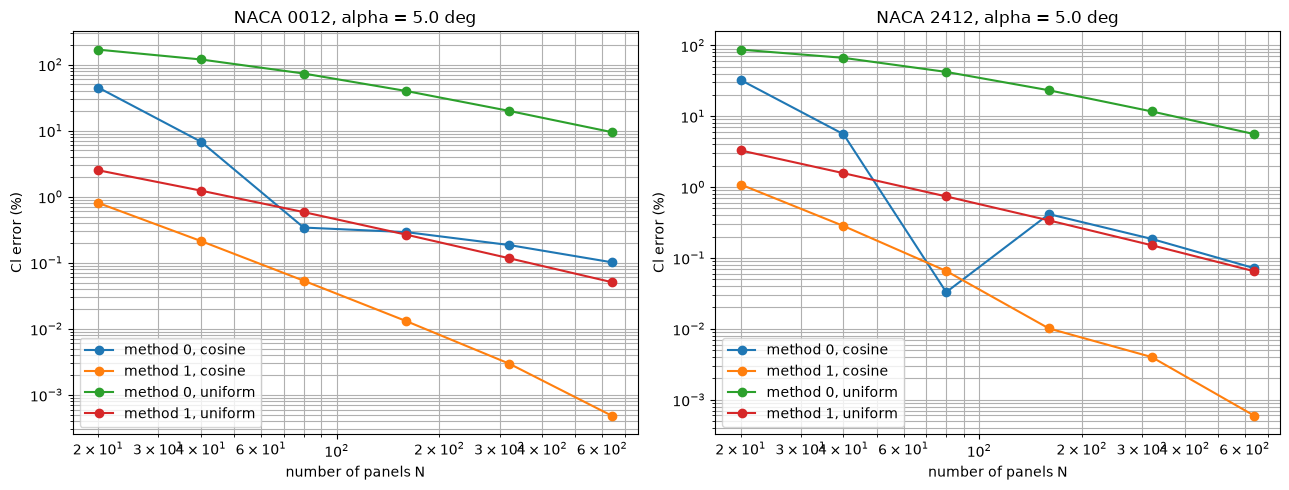

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))   # two plots side by side

airfoil_codes = ["0012", "2412"]

for i in range(2):
    code = airfoil_codes[i]
    plot_area = ax[i]

    for spacing in ["cosine", "uniform"]:
        for method_number in [0, 1]:
            error_list = errors[(code, spacing, method_number)]
            label_text = "method " + str(method_number) + ", " + spacing
            plot_area.loglog(panel_numbers, error_list, "o-", label=label_text)

    plot_area.set_title("NACA " + code + ", alpha = " + str(alpha) + " deg")
    plot_area.set_xlabel("number of panels N")
    plot_area.set_ylabel("Cl error (%)")
    plot_area.grid(True, which="both")
    plot_area.legend()

plt.tight_layout()
plt.show()

### Results: convergence of Cl with number of panels

The plots show the percentage error in Cl (relative to the N = 1000 linear-panel reference) against the number of panels N, for NACA 0012 and NACA 2412 at α = 5°.

**Effect of method.** The linear-strength method (method 1) converges much faster than the constant-strength method (method 0) for both airfoils. With cosine spacing, method 1 reaches an error below 0.001 % at N = 640, while method 0 stays near 0.1 %. A linear γ follows the real vortex distribution more closely, particularly near the leading edge.

**Effect of panel distribution.** Cosine spacing, which gives short panels near the leading and trailing edges, is far better than uniform spacing for both methods. With uniform spacing, method 0 is still about 10 % in error at N = 640 on the NACA 0012, while method 1 needs about 640 panels to reach 0.05 %. Panels must be concentrated where the surface curvature and the velocity gradients are largest.

**Rate of convergence.** Method 1 with cosine spacing shows a slope of about −2 on the log-log plot (roughly second-order); method 1 with uniform spacing shows a slope of about −1.

**Irregular behaviour of method 0.** Method 0 with cosine spacing converges quickly to about N = 80, and then flattens at about 0.1–0.3 %. The dip at N = 80 for the NACA 2412 is a chance crossing of the reference value and not a sign of better accuracy.

**Limitation.** The reference is the finest numerical solution (method 1, N = 1000), not an exact result. The errors therefore show convergence rather than absolute accuracy, and method 1 is compared with itself.

**Conclusion.** The best combination is linear strength with cosine spacing. It gives an error below 0.1 % with only 40 to 80 panels.

In [15]:
# ---- Check 1: a symmetric airfoil at zero angle should give Cl = 0 ----
xb, yb = naca4_panels("0012", 160)
result = vortex_panel_method_1(xb, yb, 0.0)
print("NACA 0012 at alpha = 0: Cl =", result["Cl"])

# ---- Check 2: zero-lift angle of NACA 2412 ----
xb, yb = naca4_panels("2412", 160)

angle1 = -2.0
angle2 = -2.2

cl1 = vortex_panel_method_1(xb, yb, angle1)["Cl"]
cl2 = vortex_panel_method_1(xb, yb, angle2)["Cl"]

# straight line through the two points, find where Cl = 0
slope = (cl2 - cl1) / (angle2 - angle1)
zero_lift_angle = angle1 - cl1 / slope

print("NACA 2412 at alpha = 0: Cl =", vortex_panel_method_1(xb, yb, 0.0)["Cl"])
print("NACA 2412 zero-lift angle =", round(zero_lift_angle, 3), "deg")
print("thin airfoil theory says about -2.08 deg")

NACA 0012 at alpha = 0: Cl = -3.9968028886505635e-15
NACA 2412 at alpha = 0: Cl = 0.25954998426736253
NACA 2412 zero-lift angle = -2.149 deg
thin airfoil theory says about -2.08 deg


### Physical checks of the linear-strength method

Two simple checks were made with `vortex_panel_method_1` (N = 160, cosine spacing).

**Check 1: symmetric airfoil at zero incidence.** A NACA 0012 at α = 0° should give zero lift by symmetry. The computed Cl is compared with zero.

**Check 2: zero-lift angle of a cambered airfoil.** The NACA 2412 has positive camber, so it should produce lift at α = 0° and reach Cl = 0 at a small negative angle α_L0. Cl was computed at α = −2.0° and −2.2°, and a straight line through these two points was used to find the angle where Cl = 0. This is valid because Cl varies linearly with α at small angles.

The result is compared with the thin airfoil theory value of about −2.08° for the NACA 2412.

**Results.** For the NACA 0012 at α = 0°, Cl = −4.0 × 10⁻¹⁵, which is zero to machine precision, as required by symmetry. For the NACA 2412, Cl = 0.2595 at α = 0° (positive, as expected for positive camber), and the zero-lift angle is −2.149°, compared with about −2.08° from thin airfoil theory.

**Discussion.** The panel method gives zero lift for the symmetric airfoil, and a zero-lift angle within about 0.07° (3 %) of thin airfoil theory for the cambered airfoil. The small difference is expected because thin airfoil theory uses only the camber line, while the panel method models the real airfoil, including thickness. The implied lift-curve slope (about 0.121 per degree, roughly 10 % above 2π per radian) is also consistent with the thickness effect. These results support the correct implementation of the linear-strength method, including the normal-velocity boundary condition and the Kutta condition.

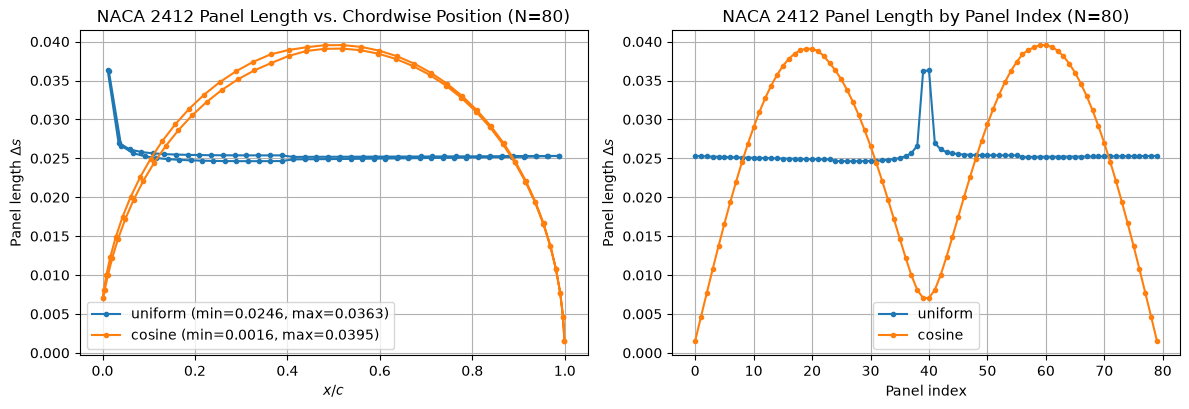

In [23]:
import numpy as np
import matplotlib.pyplot as plt

def panel_lengths(xb, yb):
    xb = np.array(xb)
    yb = np.array(yb)
    return np.hypot(np.diff(xb), np.diff(yb))

N_check = 80
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for spacing in ["uniform", "cosine"]:
    xb, yb = naca4_panels("2412", N_check, spacing)
    ds = panel_lengths(xb, yb)
    xm = 0.5 * (xb[:-1] + xb[1:])

    axes[0].plot(xm, ds, "o-", markersize=3, label=f"{spacing} (min={ds.min():.4f}, max={ds.max():.4f})")
    axes[1].plot(np.arange(len(ds)), ds, "o-", markersize=3, label=spacing)

axes[0].set_title(f"NACA 2412 Panel Length vs. Chordwise Position (N={N_check})")
axes[0].set_xlabel("$x/c$")
axes[0].set_ylabel("Panel length $\\Delta s$")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title(f"NACA 2412 Panel Length by Panel Index (N={N_check})")
axes[1].set_xlabel("Panel index")
axes[1].set_ylabel("Panel length $\\Delta s$")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

### Panel Length Distribution: Uniform vs. Cosine Spacing (NACA 2412, $N = 80$)

* **Why plot this:** Requirement 4 asks to document the effect of panel distribution with different panel lengths alongside panel count and convergence. Visualizing $\Delta s$ shows how grid clustering is placed along the airfoil surface.
* **What the plot shows:** 
  * **Uniform spacing** keeps $\Delta s \approx 0.025$ over most of the chord, with a spike near the leading edge ($\max \Delta s = 0.0363$, around panel index 40) where surface slope changes rapidly across the nose.
  * **Cosine spacing** clusters very short panels near the leading edge ($x/c \to 0$) and trailing edge ($x/c \to 1$) with $\min \Delta s = 0.0016$, while using longer panels near mid-chord ($\max \Delta s = 0.0395$).
* **Why this matters for accuracy:** High curvature and steep pressure/suction gradients occur near the leading edge, while the Kutta condition applies at the trailing edge. Concentrating fine panels there resolves sharp flow gradients without needing a huge total panel count $N$, explaining why cosine spacing converges much faster than uniform spacing.